# Credit Card Customer Segmentation Using Clustering

## 1. Import Required Libraries

This notebook applies unsupervised learning to identify customer segments from credit card usage behavior.

Pandas and NumPy are used for data handling, Matplotlib and Seaborn for visualization, and Scikit-learn for preprocessing, clustering, evaluation and dimensionality reduction. SciPy is used to construct hierarchical dendrograms.

A fixed random seed is used wherever sampling or randomized dimensionality reduction is involved so that the experiments can be reproduced.

In [7]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.pipeline import Pipeline

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the Credit Card Dataset

The dataset contains customer-level information such as balances, purchases, payments, credit limits, cash advances and purchase frequency.

The first step is to load the dataset and inspect its dimensions, column names, data types and sample records. This verifies that the file has been loaded correctly before preprocessing begins.

In [9]:
# Update this path if your CSV has a different filename or location
df = pd.read_csv("C:\\Users\\KARTHIKKHA SHREE\\OneDrive\\Desktop\\ML_CaseStudy\\data\\CC_GENERAL.csv")

print("Dataset shape:", df.shape)

display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

Dataset shape: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12



Column names:
['CUST_ID', 'BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']

Data types:
CUST_ID                                 str
BALANCE                             float64
BALANCE_FREQUENCY                   float64
PURCHASES                           float64
ONEOFF_PURCHASES                    float64
INSTALLMENTS_PURCHASES              float64
CASH_ADVANCE                        float64
PURCHASES_FREQUENCY                 float64
ONEOFF_PURCHASES_FREQUENCY          float64
PURCHASES_INSTALLMENTS_FREQUENCY    float64
CASH_ADVANCE_FREQUENCY              float64
CASH_ADVANCE_TRX                      int64
PURCHASES_TRX                         int64
CREDIT_LIMIT                        float64
PAYMENT

### Dataset Loading Observation

The dataset shape indicates the number of customer records and available attributes. The column names and data types help identify numerical financial attributes and any identifier columns.

The dataset is inspected before preprocessing so that missing values, identifier columns and unsuitable features can be handled appropriately.

## 3. Data Quality Audit

Missing values can affect distance calculations and prevent clustering algorithms from operating correctly. Duplicate records may also influence the identified customer groups.

This step examines missing values, duplicate rows, descriptive statistics and the presence of a customer identifier. The identifier `CUST_ID`, if present, is retained separately for reference but excluded from the clustering features because its numerical or categorical representation does not describe financial behavior.

In [10]:
# Preserve a working copy
df_cluster = df.copy()

# Remove accidental whitespace from column names
df_cluster.columns = df_cluster.columns.str.strip()

print("Missing values per column:")
display(
    df_cluster.isnull().sum()
    .sort_values(ascending=False)
    .to_frame("Missing Count")
)

print("\nDuplicate rows:", df_cluster.duplicated().sum())

print("\nDescriptive statistics:")
display(df_cluster.describe().T)

# Keep customer identifiers separately
if "CUST_ID" in df_cluster.columns:
    customer_ids = df_cluster["CUST_ID"].copy()
    df_cluster = df_cluster.drop(columns=["CUST_ID"])
else:
    customer_ids = pd.Series(
        df_cluster.index,
        index=df_cluster.index,
        name="Customer_Index"
    )

print("\nShape after excluding customer ID:", df_cluster.shape)

Missing values per column:


,Missing Count
MINIMUM_PAYMENTS,313
CREDIT_LIMIT,1
BALANCE,0
CUST_ID,0
BALANCE_FREQUENCY,0
PURCHASES,0
CASH_ADVANCE,0
PURCHASES_FREQUENCY,0
ONEOFF_PURCHASES,0
INSTALLMENTS_PURCHASES,0



Duplicate rows: 0

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.474828,2081.531879,0.000000,128.281915,873.385231,2054.140036,19043.13856
BALANCE_FREQUENCY,8950.0,0.877271,0.236904,0.000000,0.888889,1.000000,1.000000,1.00000
PURCHASES,8950.0,1003.204834,2136.634782,0.000000,39.635000,361.280000,1110.130000,49039.57000
ONEOFF_PURCHASES,8950.0,592.437371,1659.887917,0.000000,0.000000,38.000000,577.405000,40761.25000
INSTALLMENTS_PURCHASES,8950.0,411.067645,904.338115,0.000000,0.000000,89.000000,468.637500,22500.00000
CASH_ADVANCE,8950.0,978.871112,2097.163877,0.000000,0.000000,0.000000,1113.821139,47137.21176
PURCHASES_FREQUENCY,8950.0,0.490351,0.401371,0.000000,0.083333,0.500000,0.916667,1.00000
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.202458,0.298336,0.000000,0.000000,0.083333,0.300000,1.00000
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.364437,0.397448,0.000000,0.000000,0.166667,0.750000,1.00000
CASH_ADVANCE_FREQUENCY,8950.0,0.135144,0.200121,0.000000,0.000000,0.000000,0.222222,1.50000



Shape after excluding customer ID: (8950, 17)


### Data Audit Observation

The audit identifies attributes with missing values and reveals the ranges and distributions of financial variables. Missing values must be handled before calculating distances between customers.

Customer IDs are not valid behavioral features, so they are excluded. Duplicate records are checked and will be removed if confirmed to be accidental duplicates. Records are not removed solely because their financial values are unusual; extreme values may represent genuine customer behavior.

## 4. Data Cleaning and Feature Selection

Clustering depends on distances between observations, so missing numerical values must be handled before model fitting.

The dataset's numerical financial attributes are used as clustering features. Customer identifiers are excluded, and non-numerical columns are excluded from the numerical feature matrix unless they are explicitly encoded in a later extension.

Median imputation is used because financial variables may be skewed by customers with unusually high balances or purchases. The original dataset is preserved, and imputation is fitted later as part of the preprocessing pipeline.

In [11]:
# Select numerical features only
X = df_cluster.select_dtypes(include=np.number).copy()

# Remove columns that contain no usable information
all_missing_cols = X.columns[X.isna().all()].tolist()

if all_missing_cols:
    X = X.drop(columns=all_missing_cols)

# Remove constant features, if any
constant_cols = [
    col for col in X.columns
    if X[col].nunique(dropna=True) <= 1
]

if constant_cols:
    X = X.drop(columns=constant_cols)

print("Numerical features selected:", X.shape[1])
print("Features:", X.columns.tolist())
print("All-missing columns removed:", all_missing_cols)
print("Constant columns removed:", constant_cols)

print("\nRemaining missing values before imputation:")
display(X.isnull().sum().sort_values(ascending=False).head(10))

Numerical features selected: 17
Features: ['BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']
All-missing columns removed: []
Constant columns removed: []

Remaining missing values before imputation:


MINIMUM_PAYMENTS                    313
CREDIT_LIMIT                          1
BALANCE                               0
BALANCE_FREQUENCY                     0
PURCHASES                             0
CASH_ADVANCE                          0
PURCHASES_FREQUENCY                   0
ONEOFF_PURCHASES                      0
INSTALLMENTS_PURCHASES                0
PURCHASES_INSTALLMENTS_FREQUENCY      0
dtype: int64

### Feature Selection Observation

The selected attributes represent customer financial activity. Columns that contain no usable observations or have no variation are removed because they cannot help distinguish customers.

The feature list is checked to verify that `CUST_ID` is absent. No target variable is used because this is a customer-segmentation task without a supplied ground-truth segmentation label.

## 5. Feature Transformation and Standardization

Financial variables often have highly skewed distributions. For example, a small number of customers may have very high balances or purchase amounts.

Median imputation fills missing numerical values. The Yeo–Johnson power transformation reduces skewness and can handle zero or negative values. Standardization then places transformed features on comparable scales.

Preprocessing is fitted once on the selected clustering sample, and the same transformed matrix is used for both algorithms. This prevents differences in preprocessing from affecting the comparison.

In [12]:
# Remove rows that contain no observed feature values at all.
# These rows cannot contribute useful behavioral information.
valid_rows = X.notna().any(axis=1)

X = X.loc[valid_rows].copy()
customer_ids = customer_ids.loc[X.index]

# Use the same reproducible sample for both algorithms
sample_size = min(2000, len(X))

X_sample = X.sample(
    n=sample_size,
    random_state=RANDOM_STATE
)

# Store original-scale values for interpretation later
X_original_sample = X_sample.copy()

# Preprocessing pipeline
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("power", PowerTransformer(method="yeo-johnson")),
    ("scaler", StandardScaler())
])

X_scaled = preprocessor.fit_transform(X_sample)

print("Sample shape:", X_sample.shape)
print("Processed matrix shape:", X_scaled.shape)
print("Missing values after preprocessing:", np.isnan(X_scaled).sum())
print("Number of customers used:", len(X_sample))

Sample shape: (2000, 17)
Processed matrix shape: (2000, 17)
Missing values after preprocessing: 0
Number of customers used: 2000


### Preprocessing Observation

The transformed feature matrix contains numerical values without missing entries. Power transformation reduces the effect of strong skewness, while standardization ensures that features with larger original units do not automatically dominate the distance calculations.

The experiments use a fixed sample of up to 2,000 customers so that hierarchical clustering and visualization remain computationally manageable. Consequently, the reported clustering results describe this sample rather than necessarily representing every record in the original dataset.

## 6. Exploratory Data Analysis

Exploratory analysis helps understand the distributions of customer financial behavior before clustering.

Histograms reveal skewness, while a correlation heatmap highlights relationships among numerical features. Highly correlated attributes may describe overlapping aspects of customer behavior, and strongly skewed distributions help justify the transformation step.

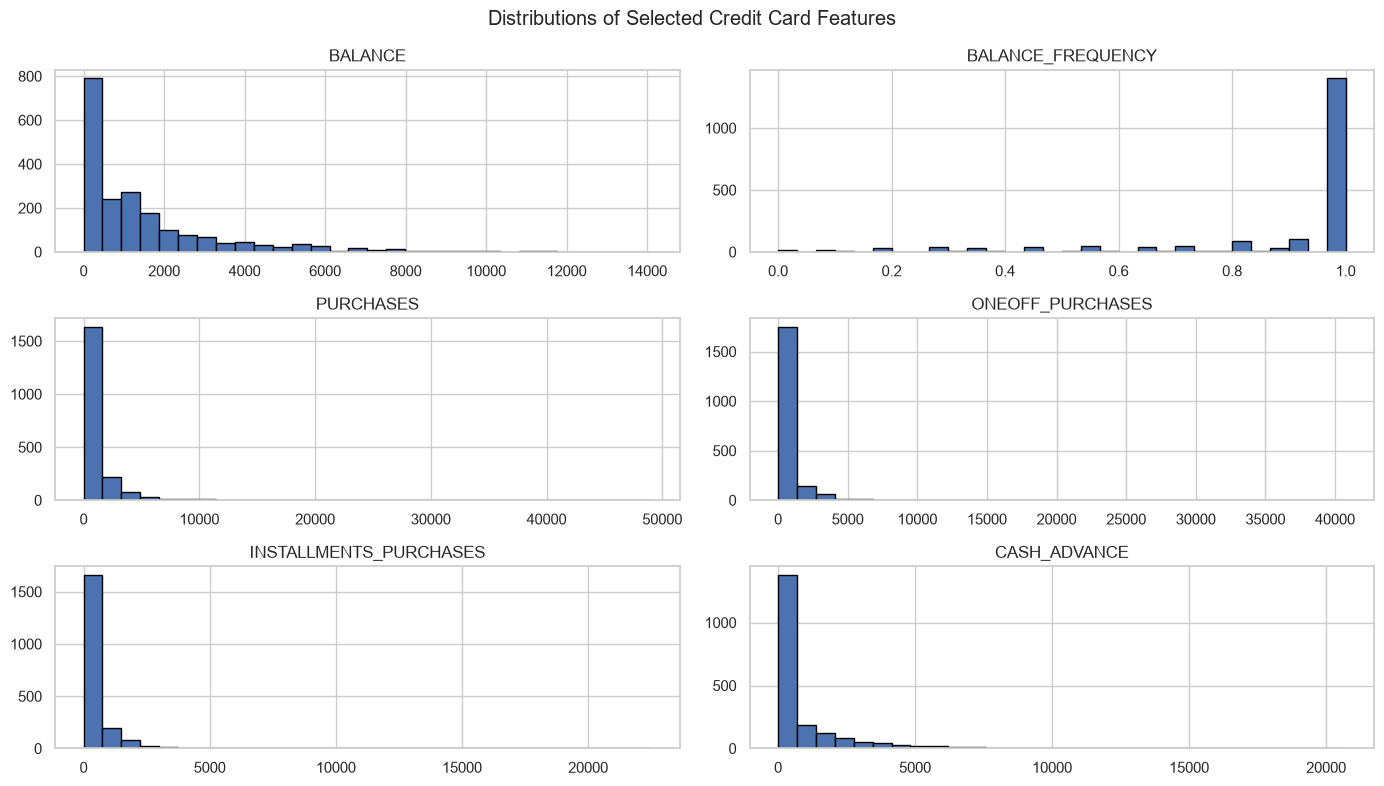

In [13]:
# Plot distributions for up to six important features
eda_cols = X_sample.columns[:min(6, len(X_sample.columns))]

X_sample[eda_cols].hist(
    figsize=(14, 8),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distributions of Selected Credit Card Features")
plt.tight_layout()
plt.show()

### Distribution Plot Observations

Examine whether the selected financial variables are approximately symmetric or strongly right-skewed. Long right tails indicate that a relatively small number of customers have larger values than most others.

These observations support the use of robust missing-value handling and power transformation. The exact findings should be written after examining the generated plots.

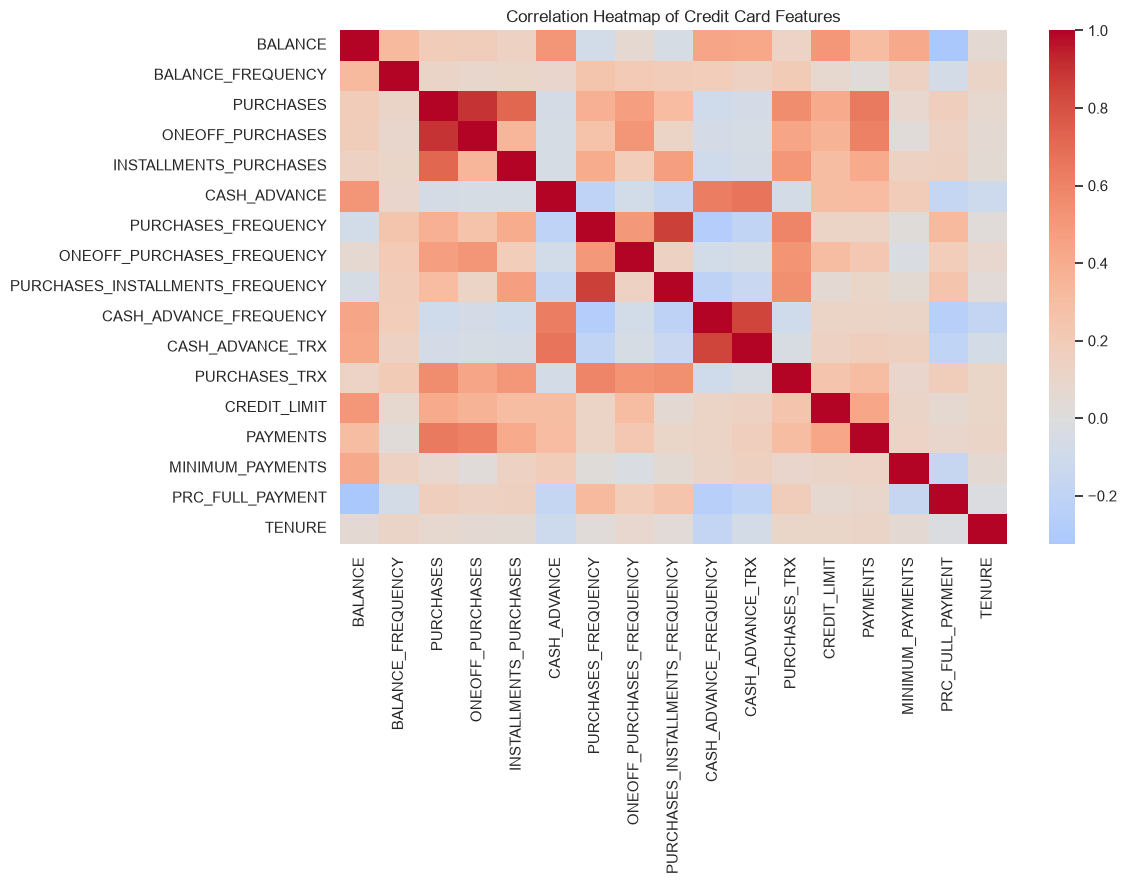

In [14]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    X_sample.corr(),
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Heatmap of Credit Card Features")
plt.tight_layout()
plt.show()

### Correlation Heatmap Observations

The heatmap displays the direction and strength of linear relationships between features. Strong positive correlations indicate that two attributes tend to increase together, while negative correlations indicate opposing relationships.

Correlation does not establish causation. The heatmap provides context for interpreting the customer segments rather than determining the clusters by itself.

## 7. K-Means Clustering and the Elbow Method

K-Means partitions observations into \(k\) clusters by assigning each observation to its nearest centroid. It iteratively updates centroids to reduce the within-cluster sum of squared distances.

The Elbow Method evaluates different values of \(k\) by recording the model's inertia. Inertia generally decreases as the number of clusters increases. The elbow is a point where adding more clusters produces a smaller improvement.

The elbow is a heuristic rather than a guaranteed optimum, so the selected cluster count will also be assessed using internal validation metrics.

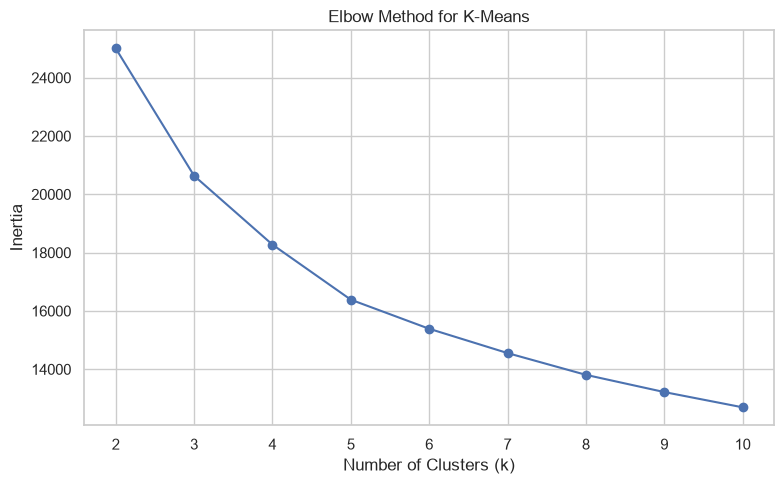

In [15]:
inertia_values = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    model.fit(X_scaled)
    inertia_values.append(model.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(list(k_values))
plt.grid(True)
plt.tight_layout()
plt.show()

### Elbow Curve Observation

The curve shows how within-cluster variation changes as the number of clusters increases. Select a candidate value near the point where the curve begins to flatten.

The final choice must be based on the actual plotted curve. Do not state that a particular cluster count is optimal before examining the output.

In [16]:
BEST_K = 4  # Change after inspecting the Elbow curve

kmeans_model = KMeans(
    n_clusters=BEST_K,
    random_state=RANDOM_STATE,
    n_init=10
)

kmeans_labels = kmeans_model.fit_predict(X_scaled)

print("K-Means completed.")
print("Clusters found:", np.unique(kmeans_labels))

print("\nCluster sizes:")
display(
    pd.Series(kmeans_labels, name="Cluster")
    .value_counts()
    .sort_index()
    .to_frame("Customer Count")
)

K-Means completed.
Clusters found: [0 1 2 3]

Cluster sizes:


,Customer Count
Cluster,
0,614
1,569
2,366
3,451


### K-Means Cluster Distribution

The cluster-size table shows how many sampled customers belong to each cluster. Large differences in cluster sizes may reflect natural differences in customer behavior, but may also indicate that some clusters contain diverse observations.

Cluster numbers are arbitrary identifiers and should not be interpreted as an ordered ranking of customer value or risk.

## 8. Hierarchical Clustering and Dendrogram Analysis

Agglomerative Hierarchical Clustering follows a bottom-up approach. Each observation initially forms its own cluster, and the algorithm repeatedly merges clusters until the specified number remains.

The linkage method determines how the distance between clusters is measured:

- **Single linkage:** Minimum distance between observations in different clusters.
- **Complete linkage:** Maximum distance between observations in different clusters.
- **Average linkage:** Average pairwise distance between observations in different clusters.

Dendrograms visualize these merging decisions. A subset is used for the dendrogram because the full hierarchy can become crowded and expensive to display.

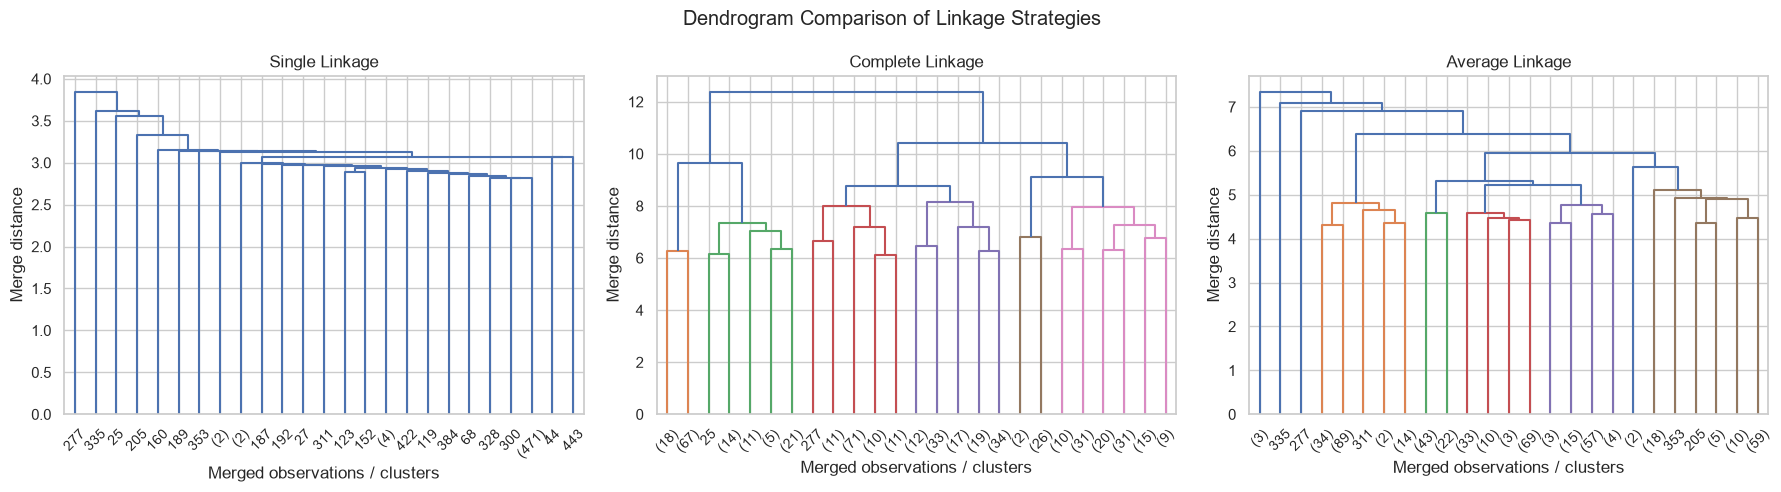

In [18]:
# Select a reproducible subset for dendrogram visualization
dendrogram_size = min(500, len(X_scaled))

rng = np.random.default_rng(RANDOM_STATE)

dendrogram_indices = np.sort(
    rng.choice(
        len(X_scaled),
        size=dendrogram_size,
        replace=False
    )
)

X_dendrogram = X_scaled[dendrogram_indices]

linkage_methods = ["single", "complete", "average"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, method in zip(axes, linkage_methods):

    Z = linkage(
        X_dendrogram,
        method=method,
        metric="euclidean"
    )

    dendrogram(
        Z,
        truncate_mode="lastp",
        p=25,
        ax=ax
    )

    ax.set_title(f"{method.capitalize()} Linkage")
    ax.set_xlabel("Merged observations / clusters")
    ax.set_ylabel("Merge distance")

plt.suptitle("Dendrogram Comparison of Linkage Strategies")
plt.tight_layout()
plt.show()

### Dendrogram Observation

The dendrograms show how the hierarchy changes with the linkage strategy. Single linkage may form long chains of observations, whereas complete linkage tends to favor tighter groups. Average linkage uses the average pairwise distance between clusters.

Large vertical gaps between merges can suggest candidate cut points. However, the dendrogram is an exploratory visualization, and the final model will be compared using the same three internal evaluation metrics as K-Means.

## 9. Fit Agglomerative Clustering

The final Agglomerative model uses Ward linkage. Ward linkage merges clusters in a way that minimizes the increase in within-cluster variance. It is compatible with Euclidean distance and works with the standardized feature representation.

The number of clusters is set to the same value selected for K-Means so that both algorithms can be compared at the same cluster count.

In [17]:
agg_model = AgglomerativeClustering(
    n_clusters=BEST_K,
    linkage="ward"
)

agg_labels = agg_model.fit_predict(X_scaled)

print("Agglomerative clustering completed.")
print("Linkage method: ward")
print("Clusters found:", np.unique(agg_labels))

print("\nCluster sizes:")
display(
    pd.Series(agg_labels, name="Cluster")
    .value_counts()
    .sort_index()
    .to_frame("Customer Count")
)

Agglomerative clustering completed.
Linkage method: ward
Clusters found: [0 1 2 3]

Cluster sizes:


,Customer Count
Cluster,
0,650
1,374
2,530
3,446


## 10. Evaluate Both Clustering Algorithms

Clustering has no supplied ground-truth labels in this customer-segmentation dataset. Therefore, internal evaluation metrics are used to assess cluster compactness and separation.

The three mandatory metrics are:

1. **Silhouette Score:** Measures how well observations fit their own clusters compared with neighboring clusters. Higher values, closer to 1, generally indicate better separation; values near zero suggest overlap, and negative values may indicate poor assignments.
2. **Davies–Bouldin Index:** Compares within-cluster spread with between-cluster separation. Lower values generally indicate better-defined clusters.
3. **Calinski–Harabasz Index:** Compares between-cluster dispersion with within-cluster dispersion. Higher values generally indicate more distinct clusters.

All metrics are calculated using the same observations and preprocessed features for both algorithms.

In [19]:
models_and_labels = {
    "K-Means": kmeans_labels,
    "Agglomerative Clustering": agg_labels
}

clustering_results = []

for model_name, labels in models_and_labels.items():

    clustering_results.append({
        "Algorithm": model_name,

        "Silhouette Score": silhouette_score(
            X_scaled,
            labels
        ),

        "Davies-Bouldin Index": davies_bouldin_score(
            X_scaled,
            labels
        ),

        "Calinski-Harabasz Index": calinski_harabasz_score(
            X_scaled,
            labels
        )
    })

clustering_results_df = pd.DataFrame(clustering_results)

display(clustering_results_df.round(4))

,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,0.2332,1.6159,572.5474
1,Agglomerative Clustering,0.1788,1.8348,452.1088


## 11. Cluster Visualization Using PCA

Principal Component Analysis (PCA) transforms the original high-dimensional feature space into a smaller number of components while retaining as much variance as possible.

The first two principal components are used to visualize the customer clusters in two dimensions. Colors indicate the cluster assignments produced by each algorithm.

PCA is used only for visualization in this section. Both clustering algorithms were fitted using the complete preprocessed feature matrix, not just the first two principal components.

Variance explained by the first two components: 0.5763


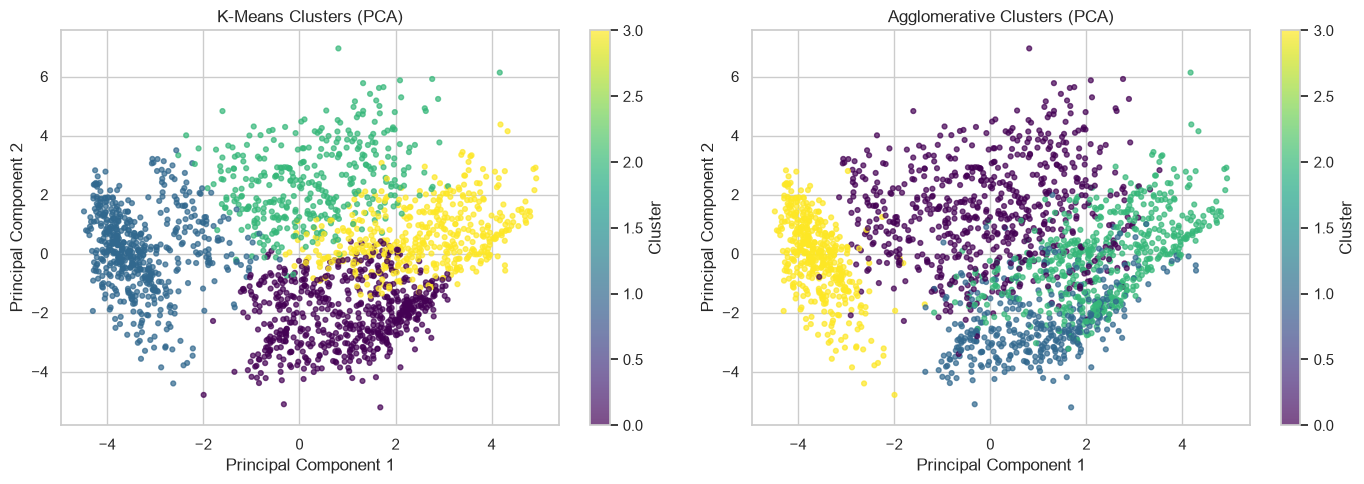

In [20]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)

X_pca = pca.fit_transform(X_scaled)

print(
    "Variance explained by the first two components:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, labels, title in [
    (axes[0], kmeans_labels, "K-Means Clusters (PCA)"),
    (axes[1], agg_labels, "Agglomerative Clusters (PCA)")
]:

    scatter = ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=labels,
        cmap="viridis",
        s=12,
        alpha=0.7
    )

    ax.set_title(title)
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

    fig.colorbar(
        scatter,
        ax=ax,
        label="Cluster"
    )

plt.tight_layout()
plt.show()

### PCA Visualization Observations

The PCA plots provide a visual comparison of the groups discovered by K-Means and Agglomerative Clustering.

Separated regions suggest visible differences among groups, while overlapping regions suggest that customers assigned to different clusters may be similar in the displayed dimensions.

PCA compresses the data, so apparent overlap in two dimensions does not necessarily mean that clusters overlap to the same degree in the original feature space. These plots should be interpreted alongside the evaluation metrics.

## 12. Cluster Visualization Using t-SNE

t-Distributed Stochastic Neighbor Embedding (t-SNE) is a nonlinear dimensionality-reduction method designed to preserve local neighborhood relationships when mapping high-dimensional observations into two dimensions.

A t-SNE plot can reveal local grouping patterns that are not clearly visible in a PCA plot. The K-Means labels are used to color the visualization, while t-SNE itself does not train or modify the clustering model.

The visualization uses a reproducible subset to limit computational cost. Its geometry should be interpreted cautiously because t-SNE does not reliably preserve global distances or cluster sizes.

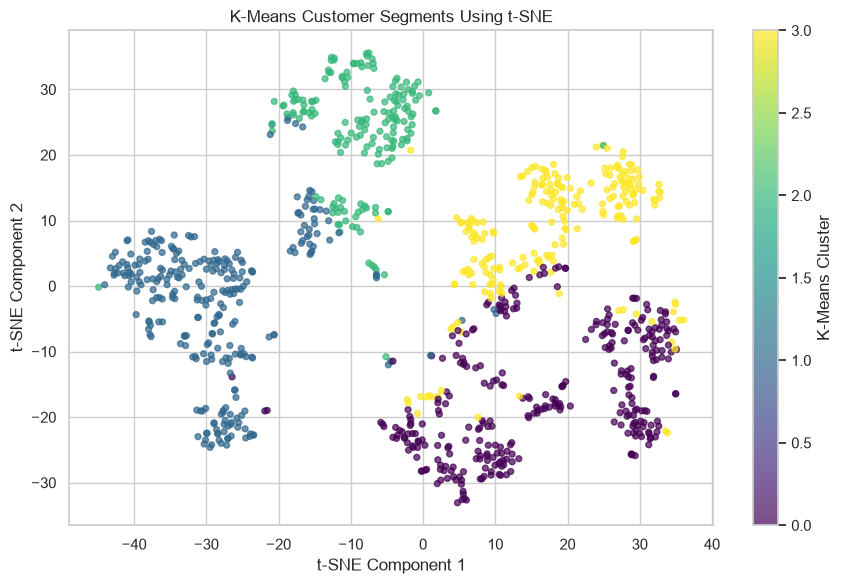

In [21]:
tsne_size = min(1000, len(X_scaled))

rng = np.random.default_rng(RANDOM_STATE)

tsne_indices = np.sort(
    rng.choice(
        len(X_scaled),
        size=tsne_size,
        replace=False
    )
)

X_tsne_input = X_scaled[tsne_indices]
tsne_labels = kmeans_labels[tsne_indices]

tsne = TSNE(
    n_components=2,
    perplexity=min(30, tsne_size - 1),
    learning_rate="auto",
    init="pca",
    random_state=RANDOM_STATE
)

X_tsne = tsne.fit_transform(X_tsne_input)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=tsne_labels,
    cmap="viridis",
    s=18,
    alpha=0.7
)

plt.colorbar(scatter, label="K-Means Cluster")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("K-Means Customer Segments Using t-SNE")
plt.tight_layout()
plt.show()

### t-SNE Visualization Observations

The t-SNE visualization provides another view of the local structure within the customer data. Visibly distinct groupings may indicate that customers have different local behavioral patterns, while mixed regions may suggest similarities between groups.

The plot is complementary to PCA and the internal metrics. t-SNE can produce visually compelling groupings even when separation in the original feature space is limited, so the plot alone is not sufficient to determine the best algorithm.